# Colab: Mapillary image ID → SAM3 auto points → MapAnything 3D measurement

这个notebook从一个Mapillary `image_id`开始，不依赖旧notebook的`/content/...` path。

Workflow:
1. 检查Colab GPU runtime和CUDA-enabled PyTorch stack。
2. 用`MAPILLARY_TOKEN`下载Mapillary image。
3. 用SAM3 text prompt自动segment road/sign object，提取top/bottom/center 2D points。
4. 用MapAnything对同一张image做metric 3D reconstruction。
5. 把SAM3 2D point映射到MapAnything output grid，snap到valid 3D point，计算distance。

Requirements:
- Colab runtime必须是GPU：`Runtime > Change runtime type > Hardware accelerator > T4 GPU`或更高。
- 需要Mapillary access token。
- 需要Hugging Face token，并且HF账号已经获得`facebook/sam3` gated model access。


<YOUR_HF_TOKEN>

In [1]:
# 0. Runtime check: run this before installing anything

import sys, os, subprocess, textwrap

print("Python:", sys.version)
try:
    import torch
    print("Torch:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())
    print("Torch CUDA:", torch.version.cuda)
    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
except Exception as e:
    print("Torch import failed:", repr(e))

if "COLAB_GPU" in os.environ:
    print("COLAB_GPU:", os.environ["COLAB_GPU"])


Python: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
Torch: 2.10.0+cu128
CUDA available: True
Torch CUDA: 12.8
GPU: Tesla T4
COLAB_GPU: 1


## 1. Clean Colab setup

Run the next cell **once** in a fresh GPU runtime. It installs one consistent PyTorch/CUDA stack, then automatically restarts the kernel. After restart, continue from section 2.

如果你刚刚已经装乱过`torch/torchvision`，建议先点：`Runtime > Disconnect and delete runtime`，再重新进GPU runtime跑这个cell。


In [ ]:
# 1. Install one consistent stack, then auto-restart runtime
# Run once. After the kernel restarts, do NOT run this cell again unless you reset runtime.

import os, sys, subprocess, textwrap

def sh(cmd):
    print("\n$ " + cmd)
    subprocess.check_call(cmd, shell=True)

# Official SAM3 README currently recommends Python 3.12+, PyTorch 2.7+, CUDA 12.6+.
# Use the official SAM3-style torch install line with CUDA 12.8 wheels.
sh("pip uninstall -y torch torchvision torchaudio")
sh("pip install -q torch==2.10.0 torchvision torchaudio --index-url https://download.pytorch.org/whl/cu128")
sh("pip install -q -U triton timm huggingface_hub requests pillow matplotlib pandas numpy opencv-python plotly")

# Install SAM3 from source. Keep torch stack fixed.
sh("rm -rf /content/sam3")
sh("git clone -q https://github.com/facebookresearch/sam3.git /content/sam3")
sh("pip install -q -e /content/sam3 --no-deps")

# Install MapAnything from source. Keep torch stack fixed.
sh("rm -rf /content/map-anything")
sh("git clone -q https://github.com/facebookresearch/map-anything.git /content/map-anything")
sh("pip install -q -e /content/map-anything --no-deps")

print("\nInstall finished. Restarting runtime now...")
os.kill(os.getpid(), 9)



$ pip uninstall -y torch torchvision torchaudio

$ pip install -q torch==2.10.0 torchvision torchaudio --index-url https://download.pytorch.org/whl/cu128

$ pip install -q -U triton timm huggingface_hub requests pillow matplotlib pandas numpy opencv-python plotly

$ rm -rf /content/sam3

$ git clone -q https://github.com/facebookresearch/sam3.git /content/sam3

$ pip install -q -e /content/sam3 --no-deps

$ rm -rf /content/map-anything

$ git clone -q https://github.com/facebookresearch/map-anything.git /content/map-anything

$ pip install -q -e /content/map-anything --no-deps


In [1]:
# 2. Post-restart sanity check

import torch, torchvision, triton, sys, os

print("Python:", sys.version)
print("Torch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Torch CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("Triton:", triton.__version__)

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is not available. Use Runtime > Change runtime type > T4 GPU, then restart."
    )

print("GPU:", torch.cuda.get_device_name(0))

from torchvision.ops import nms
print("torchvision.ops.nms OK")


Python: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
Torch: 2.10.0+cu128
Torchvision: 0.25.0+cu128
Torch CUDA: 12.8
CUDA available: True
Triton: 3.6.0
GPU: Tesla T4
torchvision.ops.nms OK


In [1]:
import os

os.environ["HF_TOKEN"] = "<YOUR_HF_TOKEN>"
os.environ["MAPILLARY_TOKEN"] = "<YOUR_MAPILLARY_TOKEN>"

In [2]:
# 3. Tokens and config

import os
from pathlib import Path

# Option A: paste tokens here temporarily
# os.environ["MAPILLARY_TOKEN"] = "YOUR_MAPILLARY_TOKEN"
# os.environ["HF_TOKEN"] = "YOUR_HUGGINGFACE_TOKEN"

# Option B: use Colab secrets named MAPILLARY_TOKEN and HF_TOKEN
try:
    from google.colab import userdata
    if not os.environ.get("MAPILLARY_TOKEN"):
        os.environ["MAPILLARY_TOKEN"] = userdata.get("MAPILLARY_TOKEN") or ""
    if not os.environ.get("HF_TOKEN"):
        os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN") or ""
except Exception:
    pass

IMAGE_ID = "842149990032290"

WORK_DIR = Path("/content/mapillary_sam3_mapanything_id")
IMAGE_DIR = WORK_DIR / "images"
OUT_DIR = WORK_DIR / "outputs"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("WORK_DIR:", WORK_DIR)
print("IMAGE_ID:", IMAGE_ID)
print("Has MAPILLARY_TOKEN:", bool(os.environ.get("MAPILLARY_TOKEN")))
print("Has HF_TOKEN:", bool(os.environ.get("HF_TOKEN")))


WORK_DIR: /content/mapillary_sam3_mapanything_id
IMAGE_ID: 842149990032290
Has MAPILLARY_TOKEN: True
Has HF_TOKEN: True


In [3]:
# 4. Hugging Face login for SAM3 gated checkpoint

import os
from huggingface_hub import login

hf_token = os.environ.get("HF_TOKEN", "")
if not hf_token:
    raise ValueError("HF_TOKEN is missing. Add it in Colab Secrets or set os.environ['HF_TOKEN'].")

login(token=hf_token, add_to_git_credential=False)
print("HF login OK")


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


HF login OK


Loaded: /content/mapillary_sam3_mapanything_id/images/842149990032290.jpg
Image size: (2560, 1920)


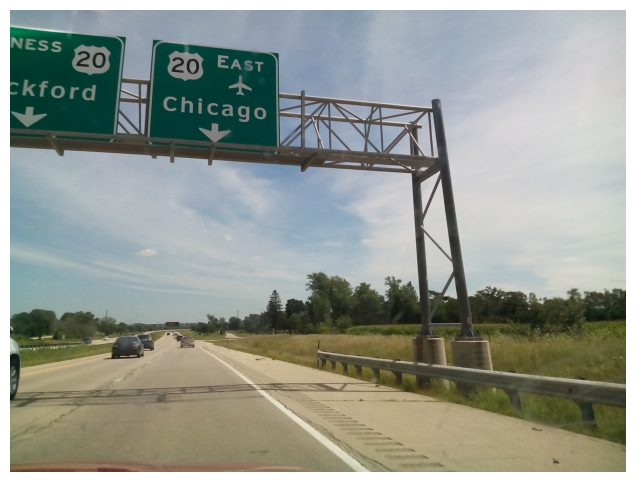

In [4]:
# 5. Download Mapillary image by image_id

import os, requests
from PIL import Image
import matplotlib.pyplot as plt

mapillary_token = os.environ.get("MAPILLARY_TOKEN", "")
if not mapillary_token:
    raise ValueError("MAPILLARY_TOKEN is missing.")

image_path = IMAGE_DIR / f"{IMAGE_ID}.jpg"
meta_path = OUT_DIR / f"{IMAGE_ID}_mapillary_meta.json"

if not image_path.exists():
    url = f"https://graph.mapillary.com/{IMAGE_ID}"
    params = {
        "fields": "id,thumb_2048_url,thumb_original_url,width,height,geometry,captured_at,compass_angle,sequence",
        "access_token": mapillary_token,
    }
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()
    meta = r.json()
    meta_path.write_text(__import__("json").dumps(meta, indent=2))

    img_url = meta.get("thumb_original_url") or meta.get("thumb_2048_url")
    if not img_url:
        raise RuntimeError("No downloadable image URL returned by Mapillary.")

    img = requests.get(img_url, timeout=120)
    img.raise_for_status()
    image_path.write_bytes(img.content)

image = Image.open(image_path).convert("RGB")
print("Loaded:", image_path)
print("Image size:", image.size)

plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.show()


In [5]:
# 6. Helper functions for SAM3 detections and measurement

import numpy as np
import pandas as pd
import cv2
from dataclasses import dataclass
from torchvision.ops import nms
import torch

@dataclass
class Detection:
    prompt: str
    score: float
    bbox_xyxy: tuple
    mask: np.ndarray

def tensor_to_numpy(x):
    if isinstance(x, torch.Tensor):
        return x.detach().float().cpu().numpy()
    return np.asarray(x)

def nms_detections(dets, iou_thr=0.5):
    if not dets:
        return []
    boxes = torch.tensor([d.bbox_xyxy for d in dets], dtype=torch.float32)
    scores = torch.tensor([d.score for d in dets], dtype=torch.float32)
    keep = nms(boxes, scores, iou_thr).cpu().numpy().tolist()
    return [dets[i] for i in keep]

def road_sign_filter(dets, image, min_area_px=60, max_area_frac=0.25):
    W, H = image.size
    out = []
    for d in dets:
        x1, y1, x2, y2 = d.bbox_xyxy
        w, h = max(1, x2 - x1), max(1, y2 - y1)
        area = w * h
        if area < min_area_px:
            continue
        if area > max_area_frac * W * H:
            continue
        if w / h > 3.5 or h / w > 6.0:
            continue
        out.append(d)
    return out

def mask_points(mask):
    ys, xs = np.where(mask > 0)
    if len(xs) == 0:
        return None
    top_i = np.argmin(ys)
    bot_i = np.argmax(ys)
    return {
        "top": (int(xs[top_i]), int(ys[top_i])),
        "bottom": (int(xs[bot_i]), int(ys[bot_i])),
        "center": (int(np.median(xs)), int(np.median(ys))),
    }

def snap_to_valid(valid, x, y, max_radius=30):
    H, W = valid.shape
    x = int(np.clip(x, 0, W - 1))
    y = int(np.clip(y, 0, H - 1))
    if valid[y, x]:
        return x, y, 0
    for r in range(1, max_radius + 1):
        y0, y1 = max(0, y-r), min(H, y+r+1)
        x0, x1 = max(0, x-r), min(W, x+r+1)
        yy, xx = np.where(valid[y0:y1, x0:x1])
        if len(xx):
            xx, yy = xx + x0, yy + y0
            k = np.argmin((xx-x)**2 + (yy-y)**2)
            return int(xx[k]), int(yy[k]), r
    return None


In [9]:
!pip install -q iopath

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 2.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sam3 0.1.0 requires ftfy==6.1.1, which is not installed.
sam3 0.1.0 requires numpy<2,>=1.26, but you have numpy 2.4.6 which is incompatible.


In [6]:
!pip install -q "numpy>=1.26,<2" "ftfy==6.1.1"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.1/53.1 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 78.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.3 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
rasterio 1.5.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
db-dtypes 1.5.1 requires pandas<3.0.0,>=1.5.3, but you have pandas 3.0.3 which is incompatible.
opencv-python 4.13.0.92 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
xarray-einstats 0.10.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
tobler 0.14.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
dask-

In [7]:
# 7. Run SAM3 text-prompt segmentation

import gc
from sam3.model_builder import build_sam3_image_model
from sam3.model.sam3_image_processor import Sam3Processor

SAM3_TEXT_PROMPTS = [
    "stop sign",
    "road sign",
    "traffic sign",
    "speed limit sign",
    "warning road sign",
    "street sign",
]

MIN_SCORE = 0.25
device = "cuda"

model = build_sam3_image_model().to(device)
model.eval()
processor = Sam3Processor(model)

raw_dets = []
with torch.inference_mode():
    with torch.autocast("cuda", dtype=torch.bfloat16):
        state = processor.set_image(image)
        for prompt in SAM3_TEXT_PROMPTS:
            out = processor.set_text_prompt(state=state, prompt=prompt)
            masks = tensor_to_numpy(out["masks"])
            boxes = tensor_to_numpy(out["boxes"])
            scores = tensor_to_numpy(out["scores"])
            print(prompt, "objects:", len(scores))
            for k, score in enumerate(scores):
                score = float(score)
                if score < MIN_SCORE:
                    continue
                mask = masks[k]
                if mask.ndim == 3:
                    mask = mask.squeeze()
                raw_dets.append(
                    Detection(
                        prompt=prompt,
                        score=score,
                        bbox_xyxy=tuple(map(int, boxes[k].tolist())),
                        mask=mask.astype(bool),
                    )
                )

sam3_detections = road_sign_filter(nms_detections(raw_dets), image)
print("Raw detections:", len(raw_dets))
print("Final detections:", len(sam3_detections))

del processor, model
gc.collect()
torch.cuda.empty_cache()


/content/sam3/sam3/model/model_misc.py:70: UserWarning: Flash Attention is disabled as it requires a GPU with Ampere (8.0) CUDA capability.
  OLD_GPU, USE_FLASH_ATTN, MATH_KERNEL_ON = get_sdpa_settings()
/usr/local/lib/python3.12/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


TypeError: expected str, bytes or os.PathLike object, not NoneType

In [ ]:
# 8. Visualize SAM3 detections and auto points

from PIL import ImageDraw
import pandas as pd

overlay = image.copy()
draw = ImageDraw.Draw(overlay)
rows = []

for i, det in enumerate(sam3_detections):
    pts = mask_points(det.mask)
    x1, y1, x2, y2 = det.bbox_xyxy
    draw.rectangle([x1, y1, x2, y2], outline="red", width=4)
    draw.text((x1, max(0, y1 - 18)), f"{i}: {det.prompt} {det.score:.2f}", fill="red")
    if pts:
        for name, (x, y) in pts.items():
            r = 6
            draw.ellipse([x-r, y-r, x+r, y+r], fill="yellow")
            rows.append({
                "det_id": i,
                "prompt": det.prompt,
                "score": det.score,
                "point_type": name,
                "x": x,
                "y": y,
                "bbox_xyxy": det.bbox_xyxy,
            })

points_df = pd.DataFrame(rows)
points_csv = OUT_DIR / "sam3_auto_2d_points.csv"
points_df.to_csv(points_csv, index=False)

overlay_path = OUT_DIR / "sam3_overlay_points.jpg"
overlay.save(overlay_path)

print("Saved:", overlay_path)
print("Saved:", points_csv)
display(points_df)

plt.figure(figsize=(10, 8))
plt.imshow(overlay)
plt.axis("off")
plt.show()


In [ ]:
# 9. Choose detection for measurement

# Default: choose highest-score detection. You can override SELECTED_DET_ID manually.
if len(sam3_detections) == 0:
    raise RuntimeError("No SAM3 detections found. Try lowering MIN_SCORE or changing prompts.")

SELECTED_DET_ID = int(np.argmax([d.score for d in sam3_detections]))
selected = sam3_detections[SELECTED_DET_ID]
selected_pts = mask_points(selected.mask)

print("Selected det_id:", SELECTED_DET_ID)
print("Prompt:", selected.prompt)
print("Score:", selected.score)
print("BBox:", selected.bbox_xyxy)
print("Points:", selected_pts)


In [ ]:
# 10. Run MapAnything on the same image

import sys, gc, os
sys.path.append("/content/map-anything")

from mapanything.models import MapAnything
from mapanything.utils.image import load_images

device = "cuda"
model = MapAnything.from_pretrained("facebook/map-anything").to(device)
model.eval()

ma_images = load_images([str(image_path)])

with torch.inference_mode():
    with torch.autocast("cuda", dtype=torch.bfloat16):
        preds = model.infer(ma_images)

pred = preds[0] if isinstance(preds, (list, tuple)) else preds

def first_item(x):
    if isinstance(x, torch.Tensor) and x.ndim >= 4 and x.shape[0] == 1:
        return x[0]
    return x

pts3d = tensor_to_numpy(first_item(pred["pts3d"]))
conf = tensor_to_numpy(first_item(pred.get("conf", np.ones(pts3d.shape[:2]))))
mask = tensor_to_numpy(first_item(pred.get("mask", np.ones(pts3d.shape[:2], dtype=bool)))).astype(bool)

np.save(OUT_DIR / "mapanything_pts3d.npy", pts3d)
np.save(OUT_DIR / "mapanything_conf.npy", conf)
np.save(OUT_DIR / "mapanything_mask.npy", mask)

print("pts3d:", pts3d.shape)
print("valid ratio:", mask.mean())

del model
gc.collect()
torch.cuda.empty_cache()


In [ ]:
# 11. Convert SAM3 points to MapAnything grid and measure 3D distance

orig_W, orig_H = image.size
ma_H, ma_W = pts3d.shape[:2]

top_x, top_y = selected_pts["top"]
bot_x, bot_y = selected_pts["bottom"]

top_ma = (round(top_x * ma_W / orig_W), round(top_y * ma_H / orig_H))
bot_ma = (round(bot_x * ma_W / orig_W), round(bot_y * ma_H / orig_H))

top_snap = snap_to_valid(mask, *top_ma, max_radius=40)
bot_snap = snap_to_valid(mask, *bot_ma, max_radius=40)

if top_snap is None or bot_snap is None:
    raise RuntimeError("Could not snap SAM3 points to valid MapAnything 3D points.")

x1, y1, r1 = top_snap
x2, y2, r2 = bot_snap

P1 = pts3d[y1, x1]
P2 = pts3d[y2, x2]
dist_m = float(np.linalg.norm(P1 - P2))
dist_ft = dist_m * 3.28084

result = {
    "image_id": IMAGE_ID,
    "det_id": SELECTED_DET_ID,
    "prompt": selected.prompt,
    "sam3_score": selected.score,
    "sam3_top_xy": (top_x, top_y),
    "sam3_bottom_xy": (bot_x, bot_y),
    "mapanything_top_xy": (x1, y1),
    "mapanything_bottom_xy": (x2, y2),
    "snap_radius_top": r1,
    "snap_radius_bottom": r2,
    "distance_m": dist_m,
    "distance_ft": dist_ft,
    "P_top": P1.tolist(),
    "P_bottom": P2.tolist(),
}

result_df = pd.DataFrame([result])
result_csv = OUT_DIR / "sam3_mapanything_auto_measurement.csv"
result_df.to_csv(result_csv, index=False)

display(result_df)
print("Saved:", result_csv)


In [ ]:
# 12. Save final overlay with measurement line

final_img = image.copy()
draw = ImageDraw.Draw(final_img)

draw.line([selected_pts["top"], selected_pts["bottom"]], fill="cyan", width=6)
for name, (x, y) in selected_pts.items():
    r = 8
    color = "lime" if name in ["top", "bottom"] else "yellow"
    draw.ellipse([x-r, y-r, x+r, y+r], fill=color)

label = f"{dist_m:.3f} m / {dist_ft:.3f} ft"
mid = (
    int((selected_pts["top"][0] + selected_pts["bottom"][0]) / 2),
    int((selected_pts["top"][1] + selected_pts["bottom"][1]) / 2),
)
draw.text((mid[0] + 10, mid[1]), label, fill="cyan")

final_path = OUT_DIR / "final_auto_measurement_overlay.jpg"
final_img.save(final_path)

print("Saved:", final_path)
plt.figure(figsize=(10, 8))
plt.imshow(final_img)
plt.axis("off")
plt.show()


## Notes

如果SAM3输出不是你想要的object，优先调这些变量：

- `SAM3_TEXT_PROMPTS`
- `MIN_SCORE`
- `SELECTED_DET_ID`

如果目标是vertical clearance，不建议长期用sign mask的top-bottom distance作为最终metric。更好的下一版是：
1. SAM3 segment sign/bridge bottom。
2. SAM3 segment road surface。
3. MapAnything把road mask里的3D points拿出来fit road plane。
4. 计算object bottom到road plane的perpendicular distance。
